**Introducción a la Ciencia de Datos 2026**  
Posgrado en Ciencias de la Computación - CICESE  
M.C. Joan Manuel Raygoza Romero

# ICD - 22: Redes neuronales recurrentes

Sesión 22 del curso. Diapositivas: [icd-22-rnn.pdf](https://github.com/husseinlopez/icd2026/blob/main/clases/icd-22-rnn.pdf)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/husseinlopez/icd2026/blob/main/icd-22-rnn.ipynb)

Usaremos **UCI Human Activity Recognition Using Smartphones (UCI HAR)** para clasificar actividades humanas con una **RNN simple**, una **LSTM** y una **GRU** en TensorFlow/Keras. ¿Puede la red distinguir entre caminar, subir escaleras y permanecer de pie a partir de una ventana de movimiento?

Ejecuta las celdas en orden en Jupyter o Colab. La primera ejecución descarga aproximadamente 61 MB. Si falta alguna dependencia, instala lo siguiente en una celda y reinicia el kernel.

~~~python
%pip install tensorflow numpy pandas matplotlib scikit-learn
~~~

## 1. Preparar y visualizar los datos

El conjunto **UCI HAR** contiene mediciones de 30 personas que llevaban un teléfono en la cintura mientras realizaban seis actividades.

| En cada ejemplo | Qué representa |
|---|---|
| **128 pasos** | Una ventana de 2.56 segundos con lecturas a 50 Hz. |
| **9 variables por paso** | Aceleración corporal, aceleración total y velocidad angular, cada una en los ejes X, Y y Z. |
| **1 etiqueta** | Caminar, subir escaleras, bajar escaleras, sentarse, estar de pie o estar acostado. |

Usamos las **señales temporales** del archivo original. Conservamos la prueba oficial y reservamos participantes completos del entrenamiento oficial para validación. Las ventanas de una persona quedan juntas en una sola partición. Ajustamos la media y desviación de cada canal únicamente con entrenamiento.

Fuente: [UCI Machine Learning Repository · Human Activity Recognition Using Smartphones](https://doi.org/10.24432/C54S4K).

60989440/Unknown 146s 2us/stepEntrenamiento: (5551, 128, 9) · 16 personas
Validación: (1801, 128, 9) · 5 personas
Prueba: (2947, 128, 9) · 9 personas


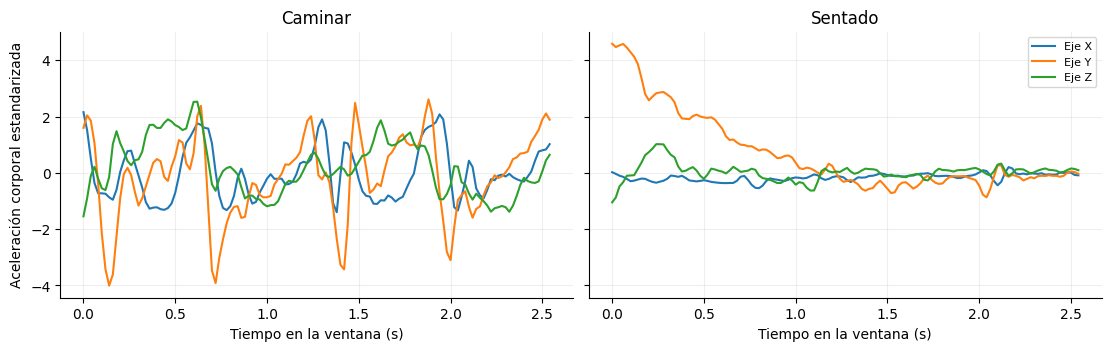

In [1]:
import os
from zipfile import ZipFile

os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "2")
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "2")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.model_selection import GroupShuffleSplit
from tensorflow import keras

SEMILLA = 42
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00240/UCI%20HAR%20Dataset.zip"
ACTIVIDADES = [
    "Caminar", "Subir escaleras", "Bajar escaleras", "Sentado", "De pie", "Acostado",
]
CANALES = [
    f"{senal}_{eje}"
    for senal in ("body_acc", "total_acc", "body_gyro")
    for eje in ("x", "y", "z")
]

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

def leer_particion(archivo, nombre):
    """Lee las ventanas como (ejemplos, pasos, canales)."""
    prefijo = f"UCI HAR Dataset/{nombre}/"

    def leer(archivo_relativo, dtype):
        with archivo.open(prefijo + archivo_relativo) as entrada:
            return np.loadtxt(entrada, dtype=dtype)

    X = np.stack([
        leer(f"Inertial Signals/{canal}_{nombre}.txt", np.float32)
        for canal in CANALES
    ], axis=-1)
    y = leer(f"y_{nombre}.txt", np.int32) - 1
    sujetos = leer(f"subject_{nombre}.txt", np.int32)
    return X, y, sujetos

ruta = keras.utils.get_file("uci-har-smartphones.zip", origin=URL)
with ZipFile(ruta) as datos:
    X_des, y_des, sujetos_des = leer_particion(datos, "train")
    X_prueba, y_prueba, sujetos_prueba = leer_particion(datos, "test")

separador = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEMILLA)
i_ent, i_val = next(separador.split(X_des, y_des, groups=sujetos_des))
X_ent, y_ent = X_des[i_ent], y_des[i_ent]
X_val, y_val = X_des[i_val], y_des[i_val]
grupos = {
    "Entrenamiento": sujetos_des[i_ent],
    "Validación": sujetos_des[i_val],
    "Prueba": sujetos_prueba,
}

media = X_ent.mean(axis=(0, 1), keepdims=True)
escala = X_ent.std(axis=(0, 1), keepdims=True)
escala = np.maximum(escala, 1e-6)
X_ent = (X_ent - media) / escala
X_val = (X_val - media) / escala
X_prueba = (X_prueba - media) / escala

for nombre, X in [("Entrenamiento", X_ent), ("Validación", X_val), ("Prueba", X_prueba)]:
    print(f"{nombre}: {X.shape} · {len(np.unique(grupos[nombre]))} personas")

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True, layout="constrained")
tiempo = np.arange(X_ent.shape[1]) / 50
for clase, ax in zip((0, 3), ejes):
    j = np.flatnonzero(y_ent == clase)[0]
    for canal, eje in enumerate(("X", "Y", "Z")):
        ax.plot(tiempo, X_ent[j, :, canal], label=f"Eje {eje}")
    ax.set(title=ACTIVIDADES[clase], xlabel="Tiempo en la ventana (s)")
    ax.grid(alpha=0.2)
ejes[0].set_ylabel("Aceleración corporal estandarizada")
ejes[1].legend(fontsize=8)
plt.show()

## 2. Entrenar y comparar RNN simple, LSTM y GRU

Es un problema **muchos a uno**. Cada modelo lee los 128 pasos y una capa densa con **softmax** transforma el último estado oculto en seis probabilidades, una por actividad.

La **RNN simple** actualiza un estado $h_t$. La **LSTM** mantiene un estado oculto $h_t$ y una memoria $c_t$. La **GRU** actualiza un único estado $h_t$ con compuertas. Las tres usan los mismos datos, tamaño de lote, ancho de estado, épocas y optimizador. El número de parámetros depende de la celda e incluye la capa de salida.

In [7]:
EPOCAS = 20
LOTE = 128
UNIDADES = 16
TASA = 0.003

CELDAS = {"RNN simple": keras.layers.SimpleRNN,
          "LSTM": keras.layers.LSTM, "GRU": keras.layers.GRU}

def crear_modelo(tipo, unidades=UNIDADES, capas=1, tasa=TASA):
    modelo = keras.Sequential([keras.Input(shape=X_ent.shape[1:])])
    for i in range(capas):
        modelo.add(CELDAS[tipo](unidades, return_sequences=(i < capas - 1)))
    modelo.add(keras.layers.Dense(len(ACTIVIDADES), activation="softmax"))
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=tasa),
        loss="sparse_categorical_crossentropy",
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
    )
    return modelo

def crear_lotes(X, y=None, mezclar=False):
    dataset = tf.data.Dataset.from_tensor_slices(X if y is None else (X, y))
    if mezclar:
        dataset = dataset.shuffle(len(y), seed=SEMILLA)
    opciones = tf.data.Options()
    opciones.threading.private_threadpool_size = 2
    return dataset.batch(LOTE).with_options(opciones).prefetch(1)

def entrenar(tipo, **configuracion):
    keras.utils.set_random_seed(SEMILLA)
    modelo = crear_modelo(tipo, **configuracion)
    historial = modelo.fit(
        crear_lotes(X_ent, y_ent, mezclar=True),
        validation_data=crear_lotes(X_val, y_val),
        epochs=EPOCAS, verbose=0, shuffle=False,
    ).history
    return modelo, historial

COLOR = {"RNN simple": "C1", "LSTM": "C0", "GRU": "C2"}
modelos_base, historiales_base = {}, {}

for tipo in CELDAS:
    print(f"Entrenando {tipo}")
    modelos_base[tipo], historiales_base[tipo] = entrenar(tipo)

def resumen(modelo, historial):
    return {
        "Parámetros entrenables": modelo.count_params(),
        "Exactitud de validación (%)": 100 * historial["val_accuracy"][-1],
        "Pérdida de validación": historial["val_loss"][-1],
    }

tabla_base = pd.DataFrame.from_dict({
    tipo: resumen(modelos_base[tipo], historiales_base[tipo])
    for tipo in CELDAS
}, orient="index").rename_axis("Modelo")
display(tabla_base.round(3))

Entrenando RNN simple
Entrenando LSTM
Entrenando GRU


,Parámetros entrenables,Exactitud de validación (%),Pérdida de validación
Modelo,,,
RNN simple,518,76.680,0.530
LSTM,1766,95.336,0.208
GRU,1398,95.447,0.209


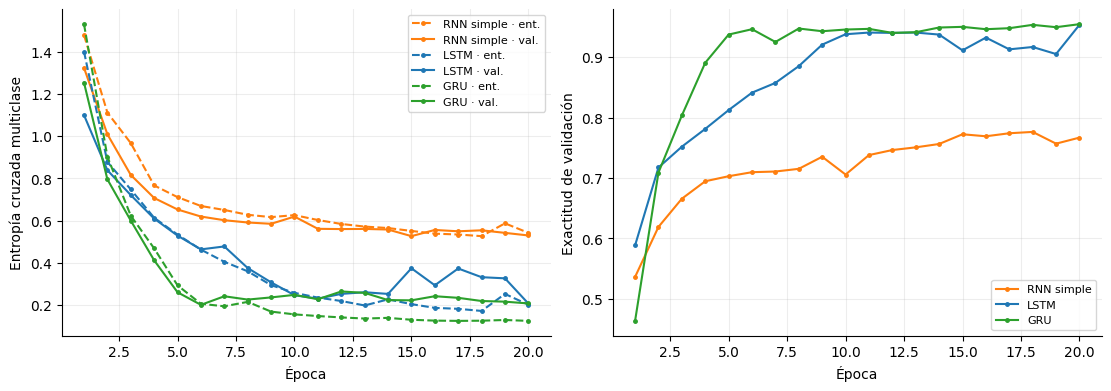

In [9]:
def trazar(ax, historial, metrica, etiqueta, color, estilo="-"):
    y = historial[metrica]
    ax.plot(range(1, len(y) + 1), y, linestyle=estilo,
            color=color, label=etiqueta, marker=".", markersize=5)

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
for tipo, historial in historiales_base.items():
    trazar(ejes[0], historial, "loss", f"{tipo} · ent.", COLOR[tipo], "--")
    trazar(ejes[0], historial, "val_loss", f"{tipo} · val.", COLOR[tipo])
    trazar(ejes[1], historial, "val_accuracy", tipo, COLOR[tipo])

for ax, etiqueta in zip(ejes, ["Entropía cruzada multiclase", "Exactitud de validación"]):
    ax.set(xlabel="Época", ylabel=etiqueta)
    ax.grid(alpha=0.22)
    ax.legend(fontsize=8)
plt.show()

## 3. Cambiar un hiperparámetro a la vez

Tomamos la **GRU** como modelo de referencia. Cambia `TIPO_EXPERIMENTO` para hacer el mismo ejercicio con la RNN simple o la LSTM.

- **Unidades.** Prueba 8 y 32 en lugar de 16. Cambia la dimensión del estado y el número de parámetros.
- **Capas recurrentes.** Prueba apilar dos capas. La primera entrega un estado por paso para que la segunda reciba una secuencia completa.
- **Tasa de aprendizaje.** Prueba dos valores alrededor de la referencia. Observa la rapidez de aprendizaje y la pérdida al final.

Cada variante se compara con la referencia en **validación**. La última época es la misma para todos los modelos. Puedes medir la sensibilidad a la inicialización repitiendo la práctica con otra semilla de entrenamiento.

Entrenando Unidades · 8 unidades
Entrenando Unidades · 32 unidades
Entrenando Capas recurrentes · 2 capas
Entrenando Tasa de aprendizaje · 0.001
Entrenando Tasa de aprendizaje · 0.006


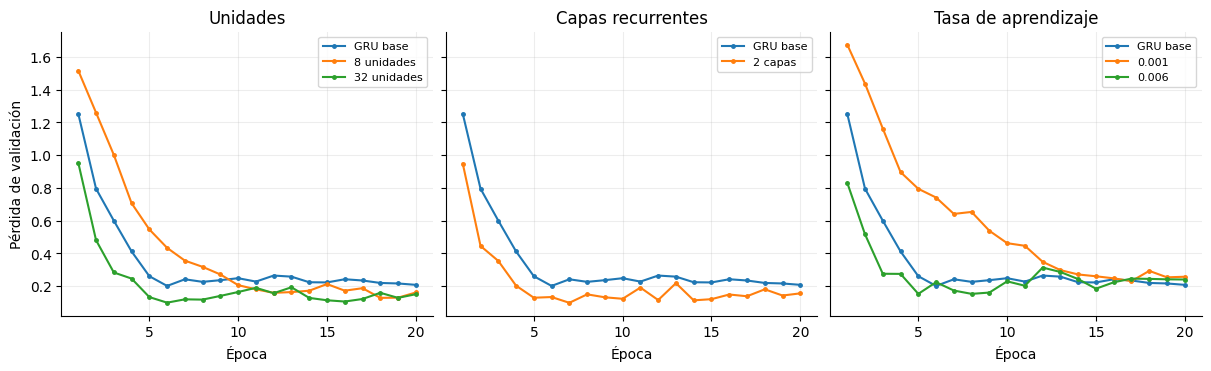

,Experimento,Configuración,Parámetros entrenables,Exactitud de validación (%),Pérdida de validación
0,Referencia,GRU,1398,95.447,0.209
1,Unidades,8 unidades,510,95.447,0.162
2,Unidades,32 unidades,4326,97.002,0.152
3,Capas recurrentes,2 capas,3030,95.669,0.157
4,Tasa de aprendizaje,0.001,1398,93.337,0.258
5,Tasa de aprendizaje,0.006,1398,95.502,0.241


In [10]:
TIPO_EXPERIMENTO = "GRU"

experimentos = {
    "Unidades": [("8 unidades", {"unidades": 8}), ("32 unidades", {"unidades": 32})],
    "Capas recurrentes": [("2 capas", {"capas": 2})],
    "Tasa de aprendizaje": [("0.001", {"tasa": 0.001}), ("0.006", {"tasa": 0.006})],
}

base = modelos_base[TIPO_EXPERIMENTO]
historial_base = historiales_base[TIPO_EXPERIMENTO]
filas = [{"Experimento": "Referencia", "Configuración": TIPO_EXPERIMENTO,
          **resumen(base, historial_base)}]
fig, ejes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True, layout="constrained")

for ax, (grupo, variantes) in zip(ejes, experimentos.items()):
    trazar(ax, historial_base, "val_loss", f"{TIPO_EXPERIMENTO} base", "C0")
    for i, (etiqueta, cambios) in enumerate(variantes, start=1):
        print(f"Entrenando {grupo} · {etiqueta}")
        variante, historial = entrenar(TIPO_EXPERIMENTO, **cambios)
        trazar(ax, historial, "val_loss", etiqueta, f"C{i}")
        filas.append({"Experimento": grupo, "Configuración": etiqueta,
                      **resumen(variante, historial)})
    ax.set(title=grupo, xlabel="Época")
    ax.grid(alpha=0.22)
    ax.legend(fontsize=8)

ejes[0].set_ylabel("Pérdida de validación")
plt.show()
tabla_variantes = pd.DataFrame(filas)
display(tabla_variantes.round(3))

## 4. Evaluar en prueba y alterar el orden de las lecturas

Evaluamos las **tres configuraciones base** sobre los participantes de la prueba oficial. La **exactitud** cuenta la proporción de aciertos. **F1 macro** promedia el F1 de las seis actividades con el mismo peso para cada clase.

Para explorar cuánto influye el orden, volvemos a evaluar los mismos modelos con las lecturas de cada ventana **permutadas al azar**. Aplicamos una sola permutación por ventana a sus nueve canales, de modo que estos permanecen sincronizados. Los tres modelos reciben exactamente las mismas ventanas permutadas.

Una caída refleja la sensibilidad a esta alteración. La permutación también genera movimientos que los sensores difícilmente registrarían, por lo que la diferencia mezcla el efecto del orden con un cambio de distribución.

,Exactitud original (%),F1 macro original (%),Exactitud con orden permutado (%),Caída (pp)
Modelo,,,,
RNN simple,71.80,70.85,66.44,5.36
LSTM,88.16,88.20,70.68,17.48
GRU,90.77,90.81,73.33,17.44


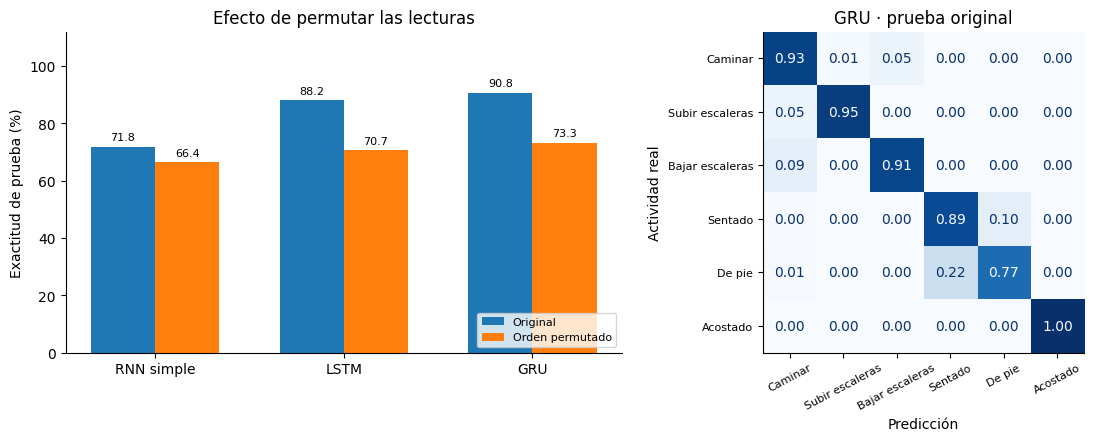

In [11]:
def predecir(modelo, X):
    return modelo.predict(crear_lotes(X), verbose=0).argmax(axis=1)

rng = np.random.default_rng(SEMILLA)
orden = rng.random(X_prueba.shape[:2]).argsort(axis=1)
X_permutada = np.take_along_axis(X_prueba, orden[..., None], axis=1)

predicciones, filas = {}, []
for tipo, modelo in modelos_base.items():
    pred = predecir(modelo, X_prueba)
    pred_permutada = predecir(modelo, X_permutada)
    predicciones[tipo] = pred
    exactitud = 100 * accuracy_score(y_prueba, pred)
    permutada = 100 * accuracy_score(y_prueba, pred_permutada)
    filas.append({
        "Modelo": tipo,
        "Exactitud original (%)": exactitud,
        "F1 macro original (%)": 100 * f1_score(y_prueba, pred, average="macro"),
        "Exactitud con orden permutado (%)": permutada,
        "Caída (pp)": exactitud - permutada,
    })
tabla_prueba = pd.DataFrame(filas).set_index("Modelo")
display(tabla_prueba.round(2))

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.3), layout="constrained")
x = np.arange(len(CELDAS))
ancho = 0.34
for diferencia, columna, etiqueta, color in [
    (-ancho/2, "Exactitud original (%)", "Original", "C0"),
    (ancho/2, "Exactitud con orden permutado (%)", "Orden permutado", "C1"),
]:
    barras = ejes[0].bar(x + diferencia, tabla_prueba[columna], ancho,
                         label=etiqueta, color=color)
    ejes[0].bar_label(barras, fmt="%.1f", padding=3, fontsize=8)

ejes[0].set(title="Efecto de permutar las lecturas",
            ylabel="Exactitud de prueba (%)", ylim=(0, 112),
            xticks=x, xticklabels=tabla_prueba.index)
ejes[0].legend(loc="lower right", fontsize=8)

ConfusionMatrixDisplay.from_predictions(
    y_prueba, predicciones[TIPO_EXPERIMENTO],
    labels=list(range(len(ACTIVIDADES))), display_labels=ACTIVIDADES,
    normalize="true", values_format=".2f", xticks_rotation=28,
    ax=ejes[1], cmap="Blues", colorbar=False,
)
ejes[1].set(title=f"{TIPO_EXPERIMENTO} · prueba original", xlabel="Predicción",
            ylabel="Actividad real")
ejes[1].tick_params(labelsize=8)
plt.show()

## 5. Actividad para experimentar

1. **Leer las señales.** ¿Qué diferencias observas entre caminar y estar sentado? ¿Qué aportaría mirar también el giroscopio?
2. **Comparar las celdas.** ¿Cuál logra la menor pérdida de validación al finalizar? ¿Cuántos parámetros cuesta esa configuración?
3. **Cambiar la tasa.** ¿Qué variante aprende más rápido? ¿Es también la que termina con la menor pérdida de validación?
4. **Revisar los errores.** ¿Qué par de actividades se confunde con mayor frecuencia? Recuerda que cada fila de la matriz muestra la distribución de predicciones para una actividad real.
5. **Interpretar el orden.** ¿Qué modelo pierde más exactitud al permutar los pasos? ¿Qué propiedades de una ventana pueden seguir distinguiendo actividades aunque cambie el orden?

### Declaración de uso de IA generativa

Este notebook fue elaborado con apoyo de ChatGPT 6.1 Sol X-High para estructurar el contenido a partir de las diapositivas de la sesión y redactar el texto explicativo. El diseño pedagógico, la selección de temas y la revisión final son responsabilidad del titular del curso.